# LEVEL 1 — TASK 1: EDA on Retail Sales Data

**Objective:** Perform Exploratory Data Analysis on retail sales data to uncover sales patterns, customer behaviour trends, product performance, and actionable business insights.

**Tech Stack:** Python, pandas, NumPy, matplotlib, seaborn, Jupyter Notebook

**Dataset:** The notebook expects `retail_sales_dataset.csv` in the same folder. A common Kaggle-style retail dataset contains fields such as Date, Customer ID, Gender, Age, Product Category, Quantity, Price per Unit and Total Amount.


In [5]:
# Install/import required libraries
# If needed, uncomment the next line:
# !pip install pandas numpy matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")


Libraries imported successfully!


In [6]:
# Load dataset
file_path = "retail_sales_dataset.csv"
df = pd.read_csv(file_path)

print(f"Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())


Dataset loaded: 1,000 rows × 8 columns


,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,2023-01-01,CUST0176,Female,43,Clothing,1,200,200
1,2023-01-01,CUST0450,Male,64,Beauty,3,100,300
2,2023-01-01,CUST0483,Female,40,Clothing,2,200,400
3,2023-01-01,CUST0226,Female,58,Beauty,3,40,120
4,2023-01-01,CUST0459,Male,18,Beauty,3,300,900


In [7]:
# Clean column names
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("-", "_", regex=False)
)

print(df.columns.tolist())


['date', 'customer_id', 'gender', 'age', 'product_category', 'quantity', 'price_per_unit', 'total_amount']


In [8]:
# Initial inspection
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values:")
missing = pd.DataFrame({
    "null_count": df.isna().sum(),
    "null_percent": (df.isna().mean() * 100).round(2)
})
display(missing)

print("Duplicate rows:", df.duplicated().sum())


Shape: (1000, 8)

Columns:
['date', 'customer_id', 'gender', 'age', 'product_category', 'quantity', 'price_per_unit', 'total_amount']

Data types:


,dtype
date,str
customer_id,str
gender,str
age,int64
product_category,str
quantity,int64
price_per_unit,int64
total_amount,int64



Missing values:


,null_count,null_percent
date,0,0.0
customer_id,0,0.0
gender,0,0.0
age,0,0.0
product_category,0,0.0
quantity,0,0.0
price_per_unit,0,0.0
total_amount,0,0.0


Duplicate rows: 0


In [9]:
# Detect common column names automatically
def find_col(options):
    for c in options:
        if c in df.columns:
            return c
    return None

date_col = find_col(["date", "transaction_date", "order_date", "sales_date", "purchase_date"])
sales_col = find_col(["total_amount", "total_spent", "sales", "revenue", "amount", "total_sales"])
quantity_col = find_col(["quantity", "qty", "units", "units_sold"])
age_col = find_col(["age", "customer_age"])
gender_col = find_col(["gender", "sex", "customer_gender"])
product_col = find_col(["product", "product_name", "item", "item_name"])
category_col = find_col(["product_category", "category", "product_type"])
customer_col = find_col(["customer_id", "customerid", "customer"])

print("Detected columns")
for name, col in {
    "Date": date_col, "Sales": sales_col, "Quantity": quantity_col,
    "Age": age_col, "Gender": gender_col, "Product": product_col,
    "Category": category_col, "Customer": customer_col
}.items():
    print(f"{name:10}: {col}")


Detected columns
Date      : date
Sales     : total_amount
Quantity  : quantity
Age       : age
Gender    : gender
Product   : None
Category  : product_category
Customer  : customer_id


In [10]:
# Data type corrections
if date_col:
    df[date_col] = pd.to_datetime(df[date_col], errors="coerce")

for col in [sales_col, quantity_col, age_col]:
    if col:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print(df.dtypes)


date                datetime64[us]
customer_id                    str
gender                         str
age                          int64
product_category               str
quantity                     int64
price_per_unit               int64
total_amount                 int64
dtype: object


## Descriptive Statistics

For all numerical columns, we calculate mean, median, mode and standard deviation.


In [11]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

if numeric_cols:
    stats = pd.DataFrame({
        "Mean": df[numeric_cols].mean(),
        "Median": df[numeric_cols].median(),
        "Mode": df[numeric_cols].mode().iloc[0],
        "Standard Deviation": df[numeric_cols].std(),
        "Minimum": df[numeric_cols].min(),
        "Maximum": df[numeric_cols].max()
    })
    display(stats.round(2))
else:
    print("No numerical columns found.")


,Mean,Median,Mode,Standard Deviation,Minimum,Maximum
age,41.32,41.0,38,13.40,18,64
quantity,2.51,3.0,3,1.11,1,4
price_per_unit,152.65,100.0,500,138.08,25,500
total_amount,383.24,225.0,300,410.07,25,2000


## Time Series Analysis

Monthly and quarterly sales trends help identify seasonality, growth and weaker periods.


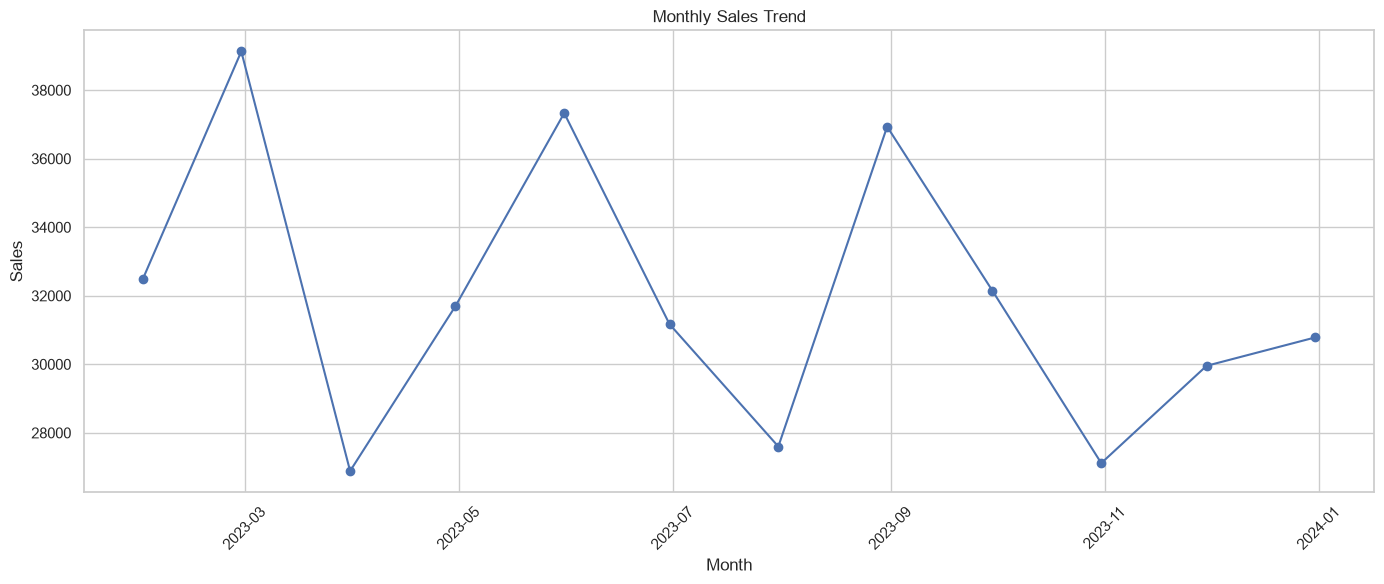

In [12]:
if date_col and sales_col:
    time_df = df.dropna(subset=[date_col, sales_col]).copy()
    time_df = time_df.set_index(date_col)

    monthly_sales = time_df[sales_col].resample("ME").sum()
    quarterly_sales = time_df[sales_col].resample("QE").sum()

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.plot(monthly_sales.index, monthly_sales.values, marker="o")
    ax.set_title("Monthly Sales Trend")
    ax.set_xlabel("Month")
    ax.set_ylabel("Sales")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Date/sales column not detected.")


### Observation

Look for the highest and lowest months, sustained upward/downward movement and repeating seasonal patterns. High-demand periods can guide inventory and marketing planning.


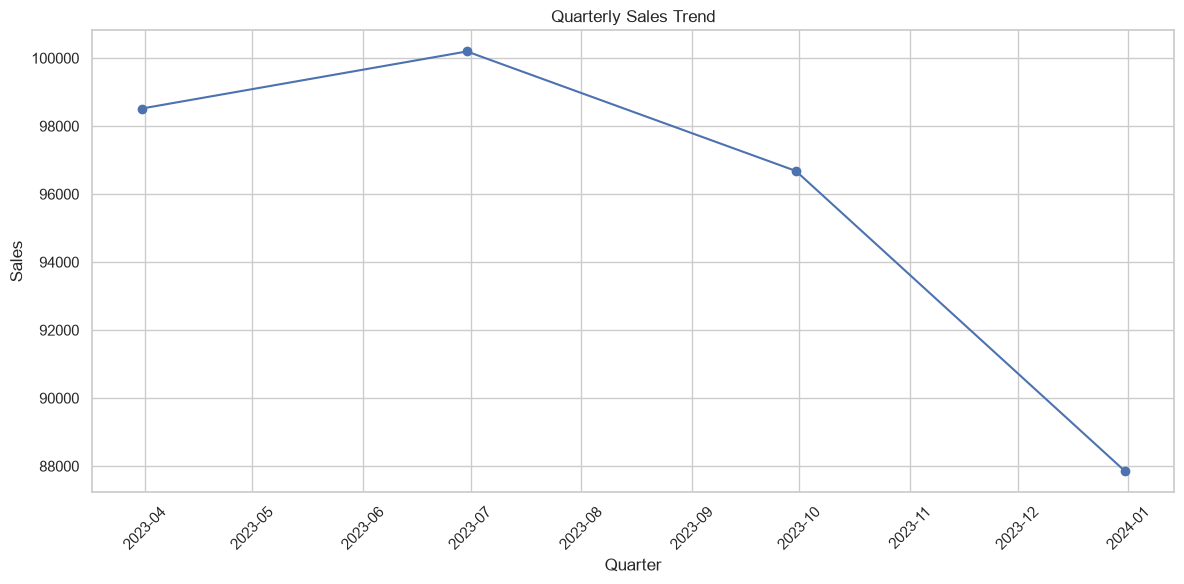

In [13]:
if date_col and sales_col:
    plt.figure(figsize=(12, 6))
    plt.plot(quarterly_sales.index, quarterly_sales.values, marker="o")
    plt.title("Quarterly Sales Trend")
    plt.xlabel("Quarter")
    plt.ylabel("Sales")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


### Observation

Quarterly aggregation gives a broader view of business performance and can reveal whether sales growth is consistent across the year.


## Customer Demographics

We analyse age groups and gender distribution to understand the customer base.


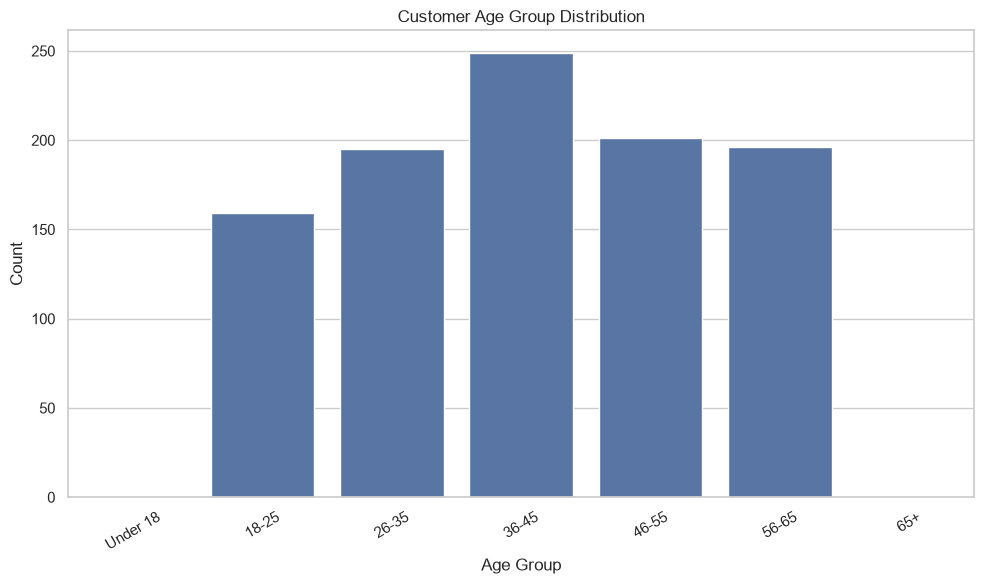

,count
age_group,
Under 18,0
18-25,159
26-35,195
36-45,249
46-55,201
56-65,196
65+,0


In [14]:
if age_col:
    bins = [0, 17, 25, 35, 45, 55, 65, 120]
    labels = ["Under 18", "18-25", "26-35", "36-45", "46-55", "56-65", "65+"]

    df["age_group"] = pd.cut(df[age_col], bins=bins, labels=labels, include_lowest=True)
    age_counts = df["age_group"].value_counts().sort_index()

    plt.figure(figsize=(10, 6))
    sns.barplot(x=age_counts.index.astype(str), y=age_counts.values)
    plt.title("Customer Age Group Distribution")
    plt.xlabel("Age Group")
    plt.ylabel("Count")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

    display(age_counts.to_frame("count"))
else:
    print("Age column not detected.")


### Observation

The largest age group represents the strongest customer concentration. This can help prioritise customer targeting and product positioning.


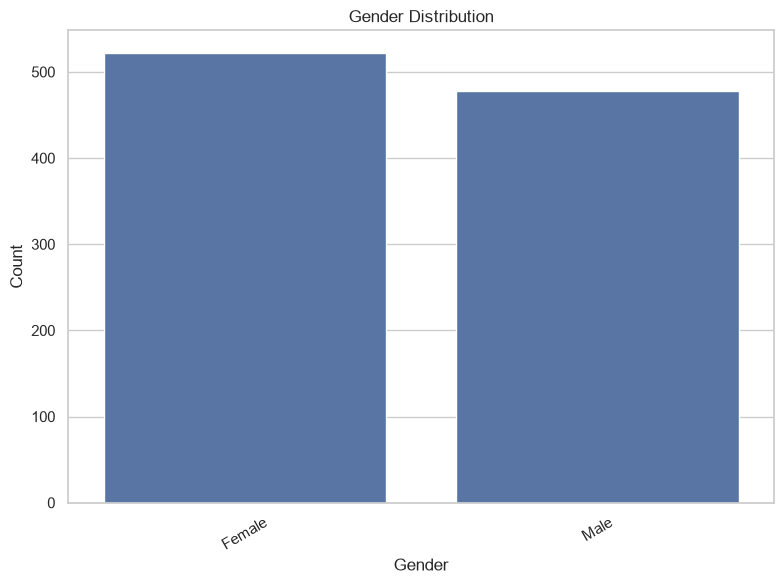

,count
gender,
Female,522
Male,478


In [15]:
if gender_col:
    gender_counts = df[gender_col].astype(str).str.strip().value_counts()

    plt.figure(figsize=(8, 6))
    sns.barplot(x=gender_counts.index, y=gender_counts.values)
    plt.title("Gender Distribution")
    plt.xlabel("Gender")
    plt.ylabel("Count")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

    display(gender_counts.to_frame("count"))
else:
    print("Gender column not detected.")


### Observation

Compare the size of each gender group. A large imbalance may suggest an opportunity to improve targeting for underrepresented customer groups.


## Product Analysis


In [16]:
if product_col:
    if quantity_col:
        top_products = (
            df.groupby(product_col)[quantity_col]
              .sum()
              .sort_values(ascending=False)
              .head(10)
        )
        metric = "Quantity Sold"
    elif sales_col:
        top_products = (
            df.groupby(product_col)[sales_col]
              .sum()
              .sort_values(ascending=False)
              .head(10)
        )
        metric = "Revenue"
    else:
        top_products = df[product_col].value_counts().head(10)
        metric = "Transactions"

    plt.figure(figsize=(12, 7))
    top_products.sort_values().plot(kind="barh")
    plt.title("Top 10 Best-Selling Products")
    plt.xlabel(metric)
    plt.ylabel("Product")
    plt.tight_layout()
    plt.show()

    display(top_products.to_frame(metric))
else:
    print("Product column not detected.")


Product column not detected.


### Observation

Top-selling products are candidates for strong inventory availability, cross-selling and targeted promotions.


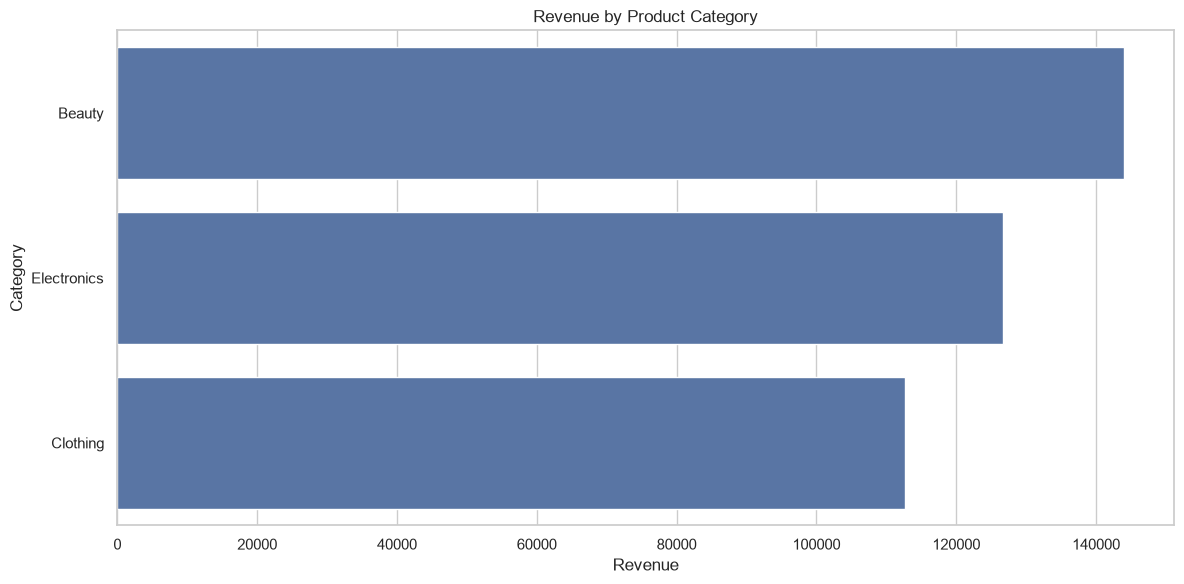

,Revenue
product_category,
Beauty,143945
Electronics,126635
Clothing,112665


In [17]:
if category_col and sales_col:
    category_revenue = (
        df.groupby(category_col)[sales_col]
          .sum()
          .sort_values(ascending=False)
    )

    plt.figure(figsize=(12, 6))
    sns.barplot(x=category_revenue.values, y=category_revenue.index)
    plt.title("Revenue by Product Category")
    plt.xlabel("Revenue")
    plt.ylabel("Category")
    plt.tight_layout()
    plt.show()

    display(category_revenue.to_frame("Revenue"))
else:
    print("Category/sales column not detected.")


### Observation

High-revenue categories should be protected from stock-outs. Low-performing categories should be investigated for pricing, demand, product mix and marketing issues.


## Correlation Heatmap

Correlation measures the strength of linear relationships between numerical variables.


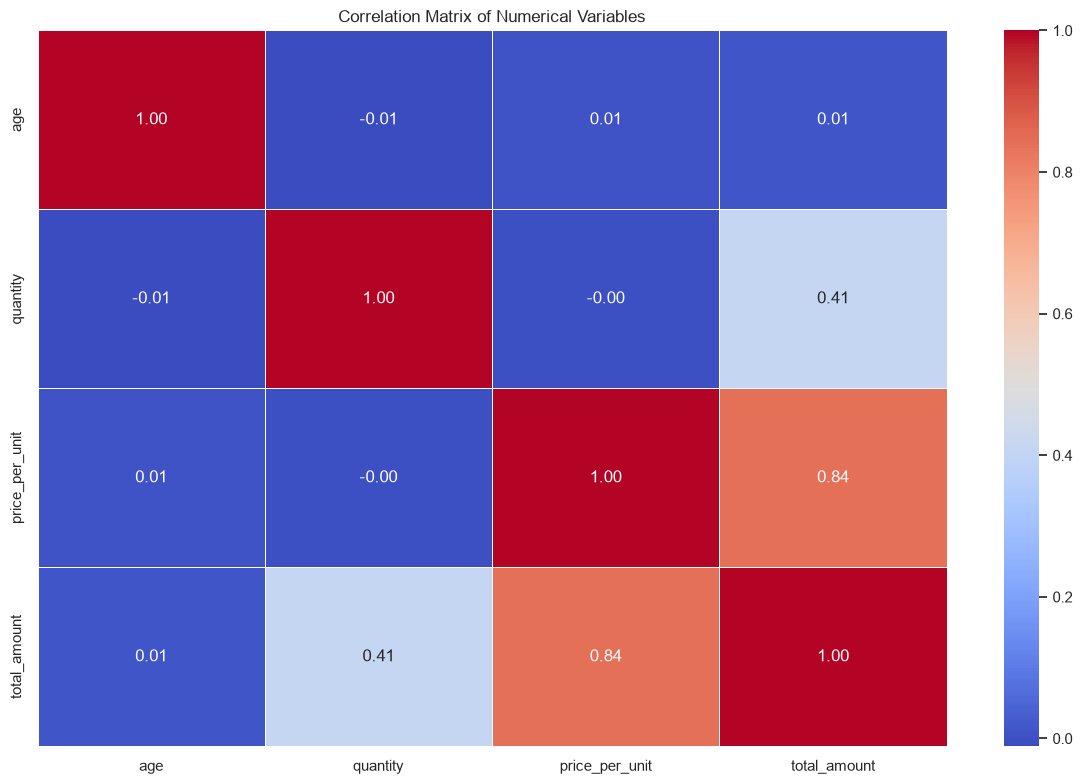

In [18]:
numeric_df = df.select_dtypes(include=np.number)

if numeric_df.shape[1] >= 2:
    corr = numeric_df.corr()

    plt.figure(figsize=(12, 8))
    sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
    plt.title("Correlation Matrix of Numerical Variables")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numerical columns for a correlation heatmap.")


### Observation

Values near +1 indicate strong positive correlation, values near -1 indicate strong negative correlation, and values near 0 indicate weak linear correlation. Correlation does not by itself prove causation.


## Additional Visualisation — Sales by Day of Week

This can reveal a non-obvious weekly purchasing pattern.


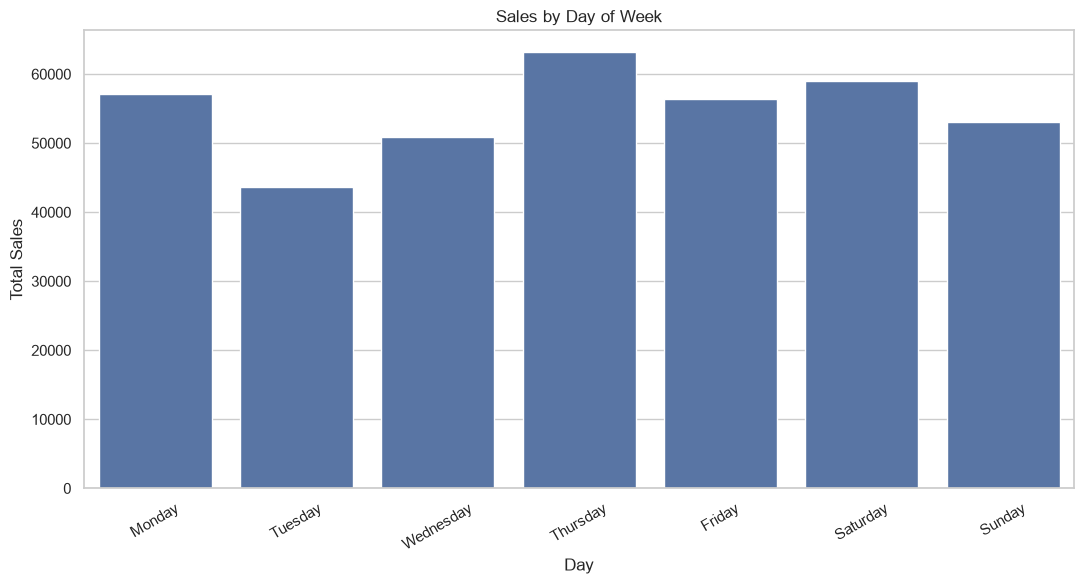

,Sales
day_of_week,
Monday,57115
Tuesday,43590
Wednesday,50875
Thursday,63160
Friday,56410
Saturday,58995
Sunday,53100


In [19]:
if date_col and sales_col:
    df["day_of_week"] = df[date_col].dt.day_name()
    day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

    weekday_sales = (
        df.groupby("day_of_week")[sales_col]
          .sum()
          .reindex(day_order)
    )

    plt.figure(figsize=(11, 6))
    sns.barplot(x=weekday_sales.index, y=weekday_sales.values)
    plt.title("Sales by Day of Week")
    plt.xlabel("Day")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

    display(weekday_sales.to_frame("Sales"))
else:
    print("Date/sales column not detected.")


### Observation

If certain days consistently generate more sales, the business can align staffing, inventory and promotional campaigns with those days.


## Additional Analysis — Sales Distribution


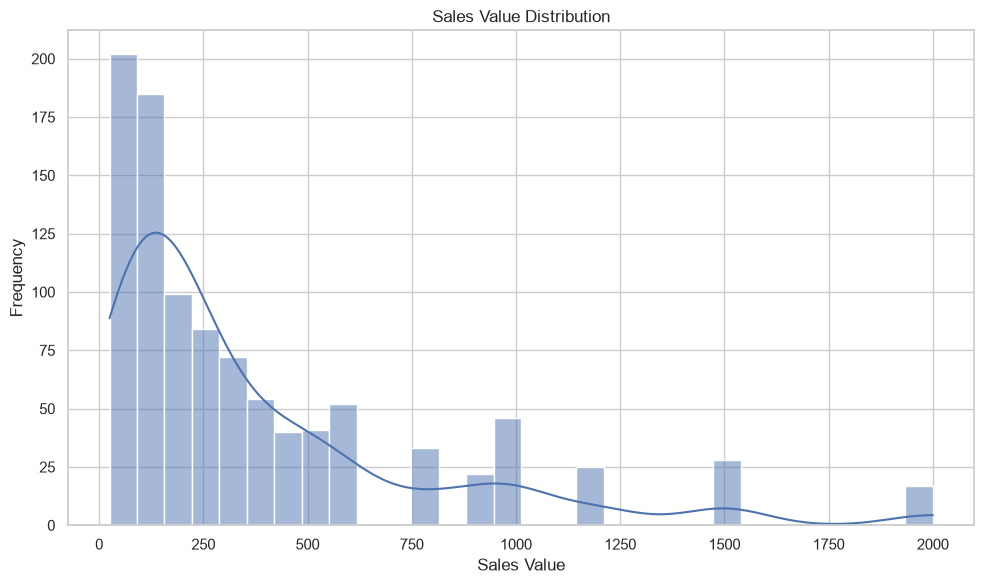

In [20]:
if sales_col:
    plt.figure(figsize=(10, 6))
    sns.histplot(df[sales_col].dropna(), bins=30, kde=True)
    plt.title("Sales Value Distribution")
    plt.xlabel("Sales Value")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()
else:
    print("Sales column not detected.")


### Observation

A strongly right-skewed distribution means a small number of high-value transactions may contribute substantially to total revenue.


## KPI Summary


In [21]:
print("=" * 55)
print("RETAIL SALES KPI SUMMARY")
print("=" * 55)

if sales_col:
    print(f"Total Revenue       : {df[sales_col].sum():,.2f}")
    print(f"Average Transaction : {df[sales_col].mean():,.2f}")
    print(f"Median Transaction  : {df[sales_col].median():,.2f}")

if quantity_col:
    print(f"Total Quantity      : {df[quantity_col].sum():,.0f}")

if customer_col:
    print(f"Unique Customers    : {df[customer_col].nunique():,}")

if product_col:
    print(f"Unique Products     : {df[product_col].nunique():,}")

if category_col:
    print(f"Unique Categories   : {df[category_col].nunique():,}")

print("=" * 55)


RETAIL SALES KPI SUMMARY
Total Revenue       : 383,245.00
Average Transaction : 383.25
Median Transaction  : 225.00
Total Quantity      : 2,511
Unique Customers    : 430
Unique Categories   : 3


# Conclusion & Actionable Business Recommendations

### 1. Protect high-performing products
Maintain sufficient stock for the top-selling products and use them for cross-selling and promotional campaigns.

### 2. Target the strongest customer segments
Use age and gender patterns to create more relevant campaigns and product recommendations.

### 3. Plan inventory around time-based demand
Use monthly and quarterly trends to prepare stock and staffing before high-demand periods.

### 4. Improve weaker categories
Investigate low-revenue categories and test targeted pricing, product mix and promotional strategies.

### 5. Use weekly sales patterns
Align promotions, staffing and inventory with the strongest sales days.

**Final takeaway:** EDA converts raw transaction data into evidence that can support marketing, inventory, customer targeting and revenue decisions.


In [22]:
# Save the analysed dataset with added analytical columns
output_file = "retail_sales_cleaned.csv"
df.to_csv(output_file, index=False)
print(f"Saved: {output_file}")


Saved: retail_sales_cleaned.csv


## Project Skills Demonstrated

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Data inspection
- Descriptive statistics
- Time-series analysis
- Customer demographics
- Product/category analysis
- Correlation analysis
- Business insight generation
